# T08 — The overseer's view

*What does the market operator see that participants do not?*

**What you will learn**

- where a book keeps its internal state, and how to read it as the market operator would: every resting
  order with its owner and its time-priority stamp, the hidden part of every iceberg, and every trade
  with both counterparties;
- what a participant sees of the same book in this simulator: the anonymous price levels, its own orders and its own trades;
- how the two views differ at one price level;
- optionally, how large the difference is on a replay of a real OMIE trading day.

**What you need**

- Previous tutorials: [T02 — Order types and matching](T02_order_types.ipynb) (icebergs) and
  [T07 — Several participants at book level](T07_several_participants.ipynb) (trade records and the side rule)
  (linked, not required).
- Run time: about 2 minutes on a central processing unit (CPU), most of it compiling the session and the replay.
- Network: no. The optional real-day cell reuses the files of [T03](T03_real_data.ipynb) only if they are
  already on disk; it never downloads.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. A small synthetic session

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. Prices are in euros per megawatt-hour (EUR/MWh) and quantities in megawatts (MW).

> **Concept — operator and participant.** In this simulator, the **market operator** is whoever runs the
> order book and sees all of it: who sent each order, the hidden part of every iceberg, and both sides of
> every trade. (In the real market, the book is the European shared order book of the Single Intraday
> Coupling (SIDC), the European continuous intraday market. OMIE receives its own participants' orders with their identities and passes them
> on anonymised. The simulator models one Iberian book, so its operator view is OMIE's view of that book.) A
> **participant** sees the book anonymously: the price levels and their visible quantities, plus its own
> orders and its own trades. In OMIE it also sees the price and volume of the trades made in its area,
> without names. This version does not offer that to a participant
> ([market specification §7](../docs/omiecid/market-spec.md#7-anonymity-and-information-visibility),
> [§9.2](../docs/omiecid/market-spec.md#92-observable-market-state-variables); OMIE Rules §45.2.12).

A `Session` replays a *tape*, the orders of other traders, and lets one participant, you, send orders
between them ([T05](T05_session.ipynb) explains it). Here the tape is written by hand with `TapeBuilder`
([T04](T04_synthetic_flow.ipynb)): eight orders from four traders, one every 30 seconds, replayed four
per step.

- Traders 7 and 9 bid 3 MW at 51.50 and 2 MW at 51.00 EUR/MWh.
- At 52.00 EUR/MWh three sellers queue: trader 7 (3 MW), trader 2 with an iceberg of 10 MW that shows
  2 MW at a time, and trader 9 (4 MW).
- Trader 4 offers 5 MW at 52.50, then buys 5 MW at 52.00: it takes trader 7's 3 MW and trader 2's
  first peak. Trader 9 adds a 1 MW bid at 51.50.

You act twice. After the first four tape orders, you sell 1 MW at 51.50, which trades with trader 7's
bid. After the last four, you send an iceberg sell of 8 MW at 52.00 that shows 4 MW at a time.

In [2]:
import dataclasses
from datetime import date, timedelta

import jax.numpy as jnp
import pandas as pd

from omiecid_simulator.jaxomiecid.omie_tape_synth import TapeBuilder
from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts
from omiecid_simulator.omiecid.contract_book import ContractBook
from omiecid_simulator.omiecid.encoding import decode_price, decode_qty, encode_price, encode_qty
from omiecid_simulator.omiecid.omie_session import AGENT_TRADER_ID, AgentOrder, Session
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side, make_order

tb = TapeBuilder(contract_id=52, first_timestamp=30, timestamp_step=30)  # one order every 30 s
tb.add(side=Side.BUY, price_eur=51.50, qty_mw=3.0, agent_id=7)
tb.add(side=Side.BUY, price_eur=51.00, qty_mw=2.0, agent_id=9)
tb.add(side=Side.SELL, price_eur=52.00, qty_mw=3.0, agent_id=7)
tb.add(side=Side.SELL, price_eur=52.00, qty_mw=10.0, agent_id=2, exec_restriction=ExecRestriction.ICE, peak_qty_mw=2.0)
tb.add(side=Side.SELL, price_eur=52.00, qty_mw=4.0, agent_id=9)
tb.add(side=Side.SELL, price_eur=52.50, qty_mw=5.0, agent_id=4)
tb.add(side=Side.BUY, price_eur=52.00, qty_mw=5.0, agent_id=4)
tb.add(side=Side.BUY, price_eur=51.50, qty_mw=1.0, agent_id=9)
tape = tb.build()  # the 8 orders, then padding rows

session = Session({"tapes": tape[None], "orders_per_step": 4})  # a set of one tape; 4 tape orders per step
pc = session.product_config  # ticks: 0.01 EUR/MWh and 0.1 MW
state = session.reset(key)
yours = [AgentOrder.create(side=Side.SELL, price=51.50, quantity=1.0),
         AgentOrder.create(side=Side.SELL, price=52.00, quantity=8.0, exec_restriction=ExecRestriction.ICE, peak_qty=4.0)]
for step, order in enumerate(yours, start=1):
    state, report, done = session.step(key, state, order)
    print(f"step {step}: {int(state.tape_cursor)} tape orders replayed; your order {int(report.order_id):,} "
          f"accepted {bool(report.submit.accepted)}, traded {float(report.submit.trade_qty):.1f} MW")
print(f"you are trader {AGENT_TRADER_ID:,}; the session numbers your orders from 2,000,000,000")

step 1: 4 tape orders replayed; your order 2,000,000,000 accepted True, traded 1.0 MW
step 2: 8 tape orders replayed; your order 2,000,000,001 accepted True, traded 0.0 MW
you are trader 1,000,000; the session numbers your orders from 2,000,000,000


## 2. Two things to know first

The next section reads the book's **internal state**, the arrays the matching engine works on.

> **This is an operator's inspection of internal state, not an interface offered to participants.**
> During trading, only the operator of the book sees this, never a participant. A participant, and any trading agent you write for a
> `Session`, must use only the participant's view of section 4.

> **The internal field layout may change between versions.** The arrays and their column positions
> below are named by constants of the package (`OrderSideFeat` and `TradesFeat` in
> `omiecid_simulator/jaxob/jaxob_constants.py`; `COL_*` in `omiecid_simulator/omiecid/iceberg_manager.py`).
> Read them through those names, never by bare column numbers, and expect to adapt the code when you
> upgrade. The column names come from the underlying order-book library: `TID` holds the trader's
> participant number, not a trade id, and `NSEC` holds the sequence number within the second, not
> nanoseconds, whatever the comments beside them say.

## 3. As the market operator

A `Session` keeps the book in `state.book`. Its order book sits in `state.book.lob` (at book level, in
`state.lob`, as in [T07](T07_several_participants.ipynb)):

- `lob.asks` and `lob.bids`: one row per resting order, with its price and its shown quantity in ticks,
  its order id, its trader, and its **time-priority stamp**. Empty rows hold $-1$.
- `lob.trades`: one row per trade, as in T07.
- `iceberg_meta`, next to `lob` in the book state: one row per live iceberg, with its order id, its side
  and its **hidden remainder** in ticks. Its first `n_active` rows are the live ones.

> **Concept — time-priority stamp.** At one price, the order with the earliest stamp trades first.
> In the market, every order gets a unique, sequential timestamp when it enters the book
> ([market specification §5.2](../docs/omiecid/market-spec.md#52-timestamp-rules)). The simulator
> stores it as a pair: the second the order entered the book, then a sequence number that orders entries
> within the same second. Our hand-written tape counts seconds from its own start, so the stamps below
> are those seconds, not clock times. A new iceberg peak gets a new stamp, which is why it waits behind the orders
> already queuing ([T02](T02_order_types.ipynb)).

The rows of `lob.asks` and `lob.bids` are storage slots, not queue positions. The helper
`operator_orders` reads them, adds each iceberg's hidden remainder, and sorts each side into queue
order: best price first, then earliest stamp. It keeps prices and quantities in ticks, so that later
checks are exact; `show_orders` decodes them for reading. The decoders `decode_price` and
`decode_qty` take one number at a time, so the conversion is done row by row, in plain Python.

In [3]:
from omiecid_simulator.jaxob.jaxob_constants import OrderSideFeat as F
from omiecid_simulator.jaxob.jaxob_constants import TradesFeat as T
from omiecid_simulator.omiecid.iceberg_manager import COL_ORDER_ID, COL_REMAINING_HIDDEN, COL_SIDE


def operator_orders(book_state):
    # Every resting order with its trader and stamp, plus each iceberg's hidden remainder, in queue order (ticks).
    meta = np.asarray(book_state.iceberg_meta)[: int(book_state.n_active)]  # the live icebergs
    hidden = {(int(m[COL_ORDER_ID]), int(m[COL_SIDE])): int(m[COL_REMAINING_HIDDEN]) for m in meta}
    rows = []
    for side, name, arr in ((Side.SELL, "ask", book_state.lob.asks), (Side.BUY, "bid", book_state.lob.bids)):
        for r in np.asarray(arr):
            if r[F.Q.value] > 0:  # an empty slot holds -1
                oid = int(r[F.OID.value])
                rows.append((name, int(r[F.P.value]), oid, int(r[F.TID.value]), int(r[F.SEC.value]),
                             int(r[F.NSEC.value]), int(r[F.Q.value]), hidden.get((oid, int(side)), 0)))
    df = pd.DataFrame(rows, columns=["side", "price", "order", "trader", "second", "seq", "shown", "hidden"])
    df["best_first"] = np.where(df.side == "ask", df.price, -df.price)
    return df.sort_values(["side", "best_first", "second", "seq"]).drop(columns="best_first").reset_index(drop=True)


def show_orders(df):
    # Decode ticks for reading: EUR/MWh and MW.
    out = df.assign(price=[f"{decode_price(p, pc):.2f}" for p in df.price],
                    shown=[f"{decode_qty(q, pc):.1f}" for q in df.shown],
                    hidden=[f"{decode_qty(q, pc):.1f}" if q else "" for q in df.hidden])
    print(out.rename(columns={"price": "price (EUR/MWh)", "shown": "shown (MW)", "hidden": "hidden (MW)",
                              "second": "stamp: second", "seq": "stamp: seq"}).to_string(index=False))


ops = operator_orders(state.book)
show_orders(ops)

side price (EUR/MWh)      order  trader  stamp: second  stamp: seq shown (MW) hidden (MW)
 ask           52.00          5       9            150           0        4.0            
 ask           52.00          4       2            210           0        2.0         6.0
 ask           52.00 2000000001 1000000            241           0        4.0         4.0
 ask           52.50          6       4            180           0        5.0            
 bid           51.50          1       7             30           0        2.0            
 bid           51.50          8       9            240           0        1.0            
 bid           51.00          2       9             60           0        2.0            


At 52.00 EUR/MWh the operator sees the true queue: trader 9's order, then trader 2's new peak, stamped
when trader 4's buy used up the first one, then your iceberg. Two icebergs hide quantity behind their
peaks. Your orders carry the stamps the session gave them, just after the tape order before them.

**Every trade, with both counterparties.** The trade records name the passive and the aggressive
trader. As in T07, the sign of the quantity gives the side: it is negative when the aggressor bought.

In [4]:
def operator_trades(book_state):
    # Every trade with its buyer, its seller and which of them was the aggressor (prices and quantities in ticks).
    rec = np.asarray(book_state.lob.trades)
    rec = rec[rec[:, T.PASS_OID.value] > 0]  # real records only
    bought = rec[:, T.Q.value] < 0  # negative quantity: the aggressor bought
    return pd.DataFrame({"price": rec[:, T.P.value], "qty": np.abs(rec[:, T.Q.value]),
                         "buyer": np.where(bought, rec[:, T.AGRS_TID.value], rec[:, T.PASS_TID.value]),
                         "seller": np.where(bought, rec[:, T.PASS_TID.value], rec[:, T.AGRS_TID.value]),
                         "aggressor": np.where(bought, "buyer", "seller")})


trades = operator_trades(state.book)
for t in trades.itertuples():
    print(f"   {decode_qty(t.qty, pc):.1f} MW at {decode_price(t.price, pc):.2f} EUR/MWh: "
          f"trader {t.buyer:,} bought from trader {t.seller:,} (the {t.aggressor} was the aggressor)")

   1.0 MW at 51.50 EUR/MWh: trader 7 bought from trader 1,000,000 (the seller was the aggressor)
   3.0 MW at 52.00 EUR/MWh: trader 4 bought from trader 7 (the buyer was the aggressor)
   2.0 MW at 52.00 EUR/MWh: trader 4 bought from trader 2 (the buyer was the aggressor)


## 4. As a participant

You see four things, all through public calls:

- the best bid and ask with their visible quantities, `session.top_of_book(state)`;
- the anonymous book, every price level with its visible quantity, `get_anonymous_lob`;
- your own resting orders, `get_agent_orders`, where an iceberg shows its **full** remaining quantity;
- your own trades, `get_agent_trades`: price, quantity and time, with no counterparty. The market
  specification also lists the side of each own trade; this version does not report it (see the gap
  table of [the certificate](../docs/omiecid/certificate.md)).

The last three are methods of `ContractBook`. A `ContractBook` holds no state of its own: it reads the
state it is given. We build one with the session's configurations and pass it `state.book`, as
[Sessions › Cancelling an order](../docs/sessions.md#cancelling-an-order) does. The package has no public
helper to open a contract, so we make an open copy with `dataclasses.replace`; reading the book does not
need it, but the first exercise sends an order.

In [5]:
contract = dataclasses.replace(generate_contracts()[52], status=ContractStatus.OPEN)  # no public "open" helper
book = ContractBook(contract, session.product_config, session.market_config)

tob = session.top_of_book(state)
print(f"top of book: bid {float(tob.p_bid):.2f} EUR/MWh for {float(tob.q_bid):.1f} MW, "
      f"ask {float(tob.p_ask):.2f} EUR/MWh for {float(tob.q_ask):.1f} MW")
bids, asks = book.get_anonymous_lob(state.book)
print("anonymous book:", " | ".join(f"ask {p:.2f}: {q:.1f} MW" for p, q in sorted(asks, reverse=True)),
      "|", " | ".join(f"bid {p:.2f}: {q:.1f} MW" for p, q in bids))
own = book.get_agent_orders(state.book, AGENT_TRADER_ID)
for o in own:
    print(f"your order {o.order_id:,}: {'sell' if o.side == Side.SELL else 'buy'} {o.quantity:.1f} MW at {o.price:.2f} EUR/MWh")
own_trades = book.get_agent_trades(state.book, AGENT_TRADER_ID)
for price, qty, ts in own_trades:
    print(f"your trade: {qty:.1f} MW at {price:.2f} EUR/MWh, at second {ts}")

top of book: bid 51.50 EUR/MWh for 3.0 MW, ask 52.00 EUR/MWh for 10.0 MW


anonymous book: ask 52.50: 5.0 MW | ask 52.00: 10.0 MW | bid 51.50: 3.0 MW | bid 51.00: 2.0 MW


your order 2,000,000,001: sell 8.0 MW at 52.00 EUR/MWh


your trade: 1.0 MW at 51.50 EUR/MWh, at second 121


The two views describe the same book. The cell below checks it, comparing whole numbers of ticks:

- at every price level, the visible quantity a participant sees is the sum of the shown parts of the
  operator's orders at that price, and the top of book agrees with the first level;
- the full quantity of your iceberg is its shown peak plus its hidden remainder in the operator's view;
- your trades are the operator's trades in which you are the buyer or the seller.

In [6]:
for side, levels in (("bid", bids), ("ask", asks)):
    for price, qty in levels:
        at = ops[(ops.side == side) & (ops.price == encode_price(price, pc))]
        assert int(at.shown.sum()) == encode_qty(qty, pc)
assert encode_qty(float(tob.q_ask), pc) == encode_qty(asks[0][1], pc)
assert encode_qty(float(tob.q_bid), pc) == encode_qty(bids[0][1], pc)
for o in own:
    mine = ops[ops.order == o.order_id].iloc[0]
    assert encode_qty(o.quantity, pc) == mine.shown + mine.hidden
in_trades = trades[(trades.buyer == AGENT_TRADER_ID) | (trades.seller == AGENT_TRADER_ID)]
assert sorted((encode_price(p, pc), encode_qty(q, pc)) for p, q, _ in own_trades) == \
    sorted(zip(in_trades.price.tolist(), in_trades.qty.tolist()))
print(f"both views agree, tick for tick: {len(bids) + len(asks)} price levels, your resting orders, your trades")

both views agree, tick for tick: 4 price levels, your resting orders, your trades


## 5. One price level, two views

The figure draws the asks at 52.00 EUR/MWh twice. The upper row is the operator's queue, front at the
left: each order is a segment with its id, its trader and its shown quantity, and the hidden parts of
the icebergs are hatched at the end. The lower row is what every participant sees in this simulator: one quantity, with no ids and no
hidden part. (OMIE's rules describe the participant's screen as an anonymous list of orders, so a real
screen may also show the separate visible orders at the level. It never shows their owners or the
hidden parts.) The drawing loop is the one of T02's queue figure.

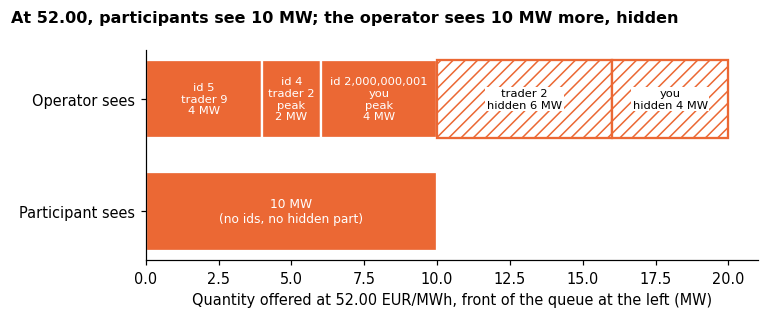

In [7]:
level = ops[(ops.side == "ask") & (ops.price == encode_price(52.00, pc))]
visible = next(q for p, q in asks if encode_price(p, pc) == encode_price(52.00, pc))
shown, hidden = [], []
for r in level.itertuples():
    who = "you" if r.trader == AGENT_TRADER_ID else f"trader {r.trader}"
    q = decode_qty(r.shown, pc)
    shown.append((f"id {r.order:,}\n{who}\n" + ("peak\n" if r.hidden else "") + f"{q:g} MW", q, False))
    if r.hidden:
        h = decode_qty(r.hidden, pc)
        hidden.append((f"{who}\nhidden {h:g} MW", h, True))
segments = shown + hidden
fig, ax = plt.subplots(figsize=(7, 2.9))
left = 0.0
for label, q, hidden in segments:
    style = dict(color="white", edgecolor=SELL, hatch="///") if hidden else dict(color=SELL, edgecolor="white")
    ax.barh(1, q, left=left, height=0.7, lw=1.5, **style)
    ax.text(left + q / 2, 1, label, ha="center", va="center", fontsize=7.5, color="black" if hidden else "white",
            bbox=dict(facecolor="white", edgecolor="none", pad=1) if hidden else None)
    left += q
ax.barh(0, visible, height=0.7, color=SELL, edgecolor="white", lw=1.5)
ax.text(visible / 2, 0, f"{visible:g} MW\n(no ids, no hidden part)", ha="center", va="center", color="white", fontsize=8)
ax.set_yticks([1, 0], ["Operator sees", "Participant sees"]); ax.grid(False)
ax.set_xlabel("Quantity offered at 52.00 EUR/MWh, front of the queue at the left (MW)")
fig.suptitle(f"At 52.00, participants see {visible:g} MW; the operator sees {decode_qty(int(level.hidden.sum()), pc):g} MW more, hidden",
             x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout()
plt.show()

## 6. A real trading day (optional)

[T03](T03_real_data.ipynb) downloads the OMIE files for contract 81 (20:15 to 20:30) delivered on 12
January 2026. If those four files are already in `<root>/data/rawOMIE`, the cell below replays the
orders sent before 18:00 on 11 January, 2 hours 40 minutes after trading opened, and compares the two
views level by level. Otherwise it prints a message and does nothing else: **it never downloads.**

Four things to keep in mind when reading the result:

- The replay keeps every order that does not trade in the book, because the public files do not say
  when an order was cancelled (T03, section 4). The real book at 18:00 was probably thinner, and some of
  the replay's trades may not have happened.
- A "trader" in this cell is one bidding unit named in OMIE's files, numbered by the loader. One
  company can own several bidding units, so "36 traders" means 36 bidding units. During trading these
  identities were known only to OMIE; it publishes them with the orders 90 days later
  ([market specification §13.5](../docs/omiecid/market-spec.md#135-domain-finding-da-unidad-2026-04-unidad-on-orders-and-trades)).
- The hidden quantities are those of the order file as loaded. T03, section 6, explains what the public
  files leave out.
- Only Iberian orders are replayed. A real participant's screen also showed orders from other
  countries that could reach Iberia through the free interconnection capacity. OMIE's public files do
  not contain them, so the column "participants see" is the anonymous view of the replayed Iberian
  book, not a real screen.

The replay needs room: up to 2,048 resting orders per side, and `book_full` tells whether that was ever
reached (T03, section 4).

In [8]:
REAL_DAY, REAL_CONTRACT = "2026-01-12", 81  # the delivery day and contract of T03
d = date.fromisoformat(REAL_DAY)
needed = [DATA_DIR / f"{kind}_{day:%Y%m%d}.1" for kind in ("orders", "trades") for day in (d - timedelta(days=1), d)]
HAVE_REAL_DAY = all(p.exists() for p in needed)
if not HAVE_REAL_DAY:
    print("Skipped: the four OMIE files of T03 (orders and trades of 11 and 12 January 2026) are not in "
          "<root>/data/rawOMIE. Run T03 once to fetch them; this cell never downloads.")
else:
    from omiecid_simulator.jaxomiecid.omie_data_config import OMIEDataConfig
    from omiecid_simulator.jaxomiecid.omie_data_loader import load_omie_orders, replay_orders_through_book
    from omiecid_simulator.omiecid.omie_config import OMIEMarketConfig

    day_tape = np.asarray(load_omie_orders(OMIEDataConfig(data_path=str(DATA_DIR), contract_id=REAL_CONTRACT,
                                                          delivery_date=REAL_DAY)))
    TIME = 6  # time column of the loader's 13-column order rows (the loader names no constant for it; T03 uses the same)
    upto = day_tape[day_tape[:, TIME] < 18 * 3600]  # tape times count seconds from 00:00 on 11 January
    real_contract = dataclasses.replace(generate_contracts()[REAL_CONTRACT], status=ContractStatus.OPEN)
    real_book = ContractBook(real_contract, market_config=OMIEMarketConfig(book_depth=2048, nTrades=4096))
    final = replay_orders_through_book(jnp.asarray(upto), real_book, jnp.zeros((0, 6), dtype=jnp.int32)).final_state
    assert not bool(final.book_full)
    real = operator_orders(final)
    print(f"{len(upto)} orders replayed. At 18:00 the book holds {len(real)} resting orders from "
          f"{real.trader.nunique()} traders; {(real.hidden > 0).sum()} icebergs hide "
          f"{real.hidden.sum() / 10:,.1f} MW behind the {real.shown.sum() / 10:,.1f} MW shown.")
    real_bids, real_asks = real_book.get_anonymous_lob(final)
    for side, anonymous in (("ask", real_asks), ("bid", real_bids)):
        levels = real[real.side == side].groupby("price", sort=False).agg(
            shown=("shown", "sum"), hidden=("hidden", "sum"), orders=("order", "size"), traders=("trader", "nunique"))
        print(f"\nbest five {side} levels   participants see   operator also sees hidden   orders   traders")
        for (price, row), (p, q) in zip(levels.head(5).iterrows(), anonymous):
            assert encode_price(p, pc) == price and encode_qty(q, pc) == row.shown  # the same book, tick for tick
            print(f"   {decode_price(price, pc):8.2f} EUR/MWh   {q:8.1f} MW   {decode_qty(row.hidden, pc):17.1f} MW"
                  f"   {row.orders:6d}   {row.traders:7d}")

424 orders replayed. At 18:00 the book holds 395 resting orders from 36 traders; 187 icebergs hide 4,716.5 MW behind the 3,120.9 MW shown.



best five ask levels   participants see   operator also sees hidden   orders   traders
     112.17 EUR/MWh        7.1 MW                 0.0 MW        1         1
     112.27 EUR/MWh        5.9 MW                 0.0 MW        1         1
     112.28 EUR/MWh        7.3 MW                 0.0 MW        1         1
     112.38 EUR/MWh        5.9 MW                 0.0 MW        1         1
     112.39 EUR/MWh        7.5 MW                 0.0 MW        1         1

best five bid levels   participants see   operator also sees hidden   orders   traders
     104.70 EUR/MWh       71.7 MW                 0.0 MW       13        13
     101.86 EUR/MWh       10.0 MW                40.0 MW        1         1
     101.85 EUR/MWh        5.0 MW               124.7 MW        1         1
     101.84 EUR/MWh       10.0 MW                40.0 MW        1         1
     101.83 EUR/MWh        5.0 MW                 5.5 MW        1         1


## Recap

- The operator's view is the book's internal state: `lob.asks` and `lob.bids` (each resting order with its
  trader and its time-priority stamp), `lob.trades` (both counterparties), and `iceberg_meta` (each
  iceberg's hidden remainder). In a `Session` they sit under `state.book`.
- Its rows are storage slots: sort by price, then stamp, to get the queue.
- In this simulator, a participant sees the anonymous levels with visible quantities only, its own
  orders with their full iceberg quantity, and its own trades without counterparty (as in OMIE) or
  side (a gap of this version). In OMIE it also sees the price and volume of the trades in its area.
- Reading the internal state is an operator's inspection, not an interface offered to participants, and
  its field layout may change between versions.

## Exercises

1. **Who trades first?** A sell of 2 MW at 51.50 EUR/MWh arrives. Use the operator's view to predict
   which resting bid it trades with, and whose it is. Then check: send it to the book with
   `book.submit_order(state.book, make_order(...))` and read `operator_trades` on the new state.
   *Hint:* at 51.50, the bid with the earliest stamp is first in the queue.
2. **What the operator knows about the best ask.** Compute the total quantity on offer at the best ask,
   shown and hidden, and compare it with `q_ask` from the top of book.
   *Hint:* sum `shown` and `hidden` over the operator's rows at that price.
3. **The real day (optional).** If the real-day cell ran, find the trader with the most hidden quantity
   in the replayed book. *Hint:* group the operator's rows by `trader`.

The solutions are in the collapsed cell at the end.

## Further reading

- [The market model](../docs/market-model.md): icebergs, timestamps and anonymity.
- [Sessions](../docs/sessions.md#the-state): the session's state, `TopOfBook` and the book state under `state.book`.
- The evidence: [the market specification](../docs/omiecid/market-spec.md), §7 (anonymity) and §9.2
  (what a participant can observe), and [the certificate](../docs/omiecid/certificate.md). Scenarios
  [C13](../notebooks/certification/C13_anonymity.ipynb) (anonymity and information visibility) and
  [C08](../notebooks/certification/C08_iceberg_regeneration.ipynb) (iceberg peaks) certify the behaviour shown here.
- Other tutorials: [T03 — Real OMIE data](T03_real_data.ipynb) for the files of the real-day cell;
  previous: [T07 — Several participants at book level](T07_several_participants.ipynb).

## Solutions

In [9]:
# Solutions to the exercises (collapsed; expand to read).
# 1. At 51.50 the front of the queue is trader 7's bid (stamp 30 s), ahead of trader 9's (240 s).
front = ops[(ops.side == "bid") & (ops.price == encode_price(51.50, pc))].iloc[0]
print(f"1. predicted: order {front.order}, trader {front.trader}, {decode_qty(front.shown, pc):g} MW shown")
after, _ = book.submit_order(state.book, make_order(contract.contract_id, Side.SELL, 51.50, 2.0, 99, 5, 300))
last = operator_trades(after).iloc[-1]  # the newest trade
print(f"   checked: {decode_qty(last.qty, pc):.1f} MW at {decode_price(last.price, pc):.2f} EUR/MWh, "
      f"trader {last.buyer} bought from trader {last.seller} (the {last.aggressor} was the aggressor)")

# 2. Shown plus hidden at the best ask, against the visible quantity of the top of book.
best = ops[(ops.side == "ask") & (ops.price == encode_price(float(tob.p_ask), pc))]
print(f"2. at {float(tob.p_ask):.2f} EUR/MWh: {decode_qty(int(best.shown.sum() + best.hidden.sum()), pc):g} MW in total, "
      f"of which the top of book shows {float(tob.q_ask):g} MW")

# 3. The trader with the most hidden quantity in the replayed real book.
if HAVE_REAL_DAY:
    top = real.groupby("trader").hidden.sum().sort_values(ascending=False)
    print(f"3. trader {top.index[0]} hides {top.iloc[0] / 10:,.1f} MW, "
          f"{top.iloc[0] / real.hidden.sum():.0%} of all hidden quantity")
else:
    print("3. Skipped: the real-day cell did not run.")

1. predicted: order 1, trader 7, 2 MW shown


   checked: 2.0 MW at 51.50 EUR/MWh, trader 7 bought from trader 5 (the seller was the aggressor)
2. at 52.00 EUR/MWh: 20 MW in total, of which the top of book shows 10 MW
3. trader 179 hides 3,291.5 MW, 70% of all hidden quantity
